# Keras Clasificación binaria

# 1.Importación librerías

In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Creación del modelo y carga de Librerías

In [103]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation,Dropout

import pandas as pd
import numpy as np

In [104]:
X_train = pd.read_csv('../data/processed/X_train_binario.csv')
y_train = pd.read_csv('../data/processed/Y_train_binario.csv')
X_test = pd.read_csv('../data/processed/X_test_binario.csv')
y_test = pd.read_csv('../data/processed/Y_test_binario.csv')

X_train.shape

num_neuronas = X_train.shape[1]

# 2. Entrenamiento del modelo

### 2.1. Uso del Early Stopping pero sin DropOut Layers

In [105]:
model = Sequential()
model.add(Dense(units=num_neuronas,activation='relu'))
model.add(Dense(units=int(np.round(num_neuronas / 3)), activation='relu'))
#model.add(Dense(units=np.round(num_neuronas/2),activation='relu')) SENTENCIA ORIGINAL
model.add(Dense(units=1,activation='sigmoid')) 
model.compile(loss='binary_crossentropy', optimizer='adam')

In [106]:
from tensorflow.keras.callbacks import EarlyStopping

In [107]:
early_stop = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=5)

In [108]:
model.fit(x=X_train, 
          y=y_train, 
          epochs=600,
          validation_split=0.20, verbose=1,
          callbacks=[early_stop]
          )

Epoch 1/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.7856 - val_loss: 0.6584
Epoch 2/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6170 - val_loss: 0.6018
Epoch 3/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5878 - val_loss: 0.5892
Epoch 4/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5635 - val_loss: 0.5687
Epoch 5/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5440 - val_loss: 0.5514
Epoch 6/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5228 - val_loss: 0.5359
Epoch 7/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5015 - val_loss: 0.5207
Epoch 8/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4853 - val_loss: 0.5122
Epoch 9/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4710 - val_loss: 0.5077
Epoch 10/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4636 - val_loss: 0.5088
Epoch 11/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4542 - val_loss: 0.5026
Epoch 12/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4

<Axes: >

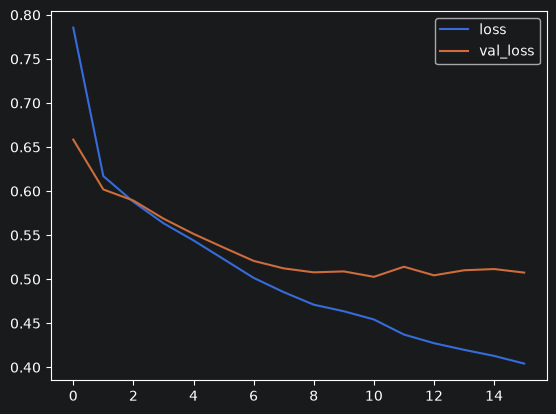

In [109]:
model_loss = pd.DataFrame(model.history.history)
model_loss.plot()

### 2.2. Modelo que emplea tanto Early Stopping así como DropOut Layers

In [110]:
from tensorflow.keras.layers import Dropout

In [111]:
model = Sequential()

model.add(Dense(units=num_neuronas,activation='relu'))
model.add(Dropout(0.5)) #la mitad de las neuronas en cada epoch para esta capa

# model.add(Dense(units=np.round(num_neuronas/2),activation='relu')) SENTENCIA ORIGINAL
model.add(Dense(units=int(np.round(num_neuronas / 2)), activation='relu'))
model.add(Dropout(0.5)) #la mitad de las neuronas en cada epoch para esta capa

model.add(Dense(units=1,activation='sigmoid'))
model.compile(loss='binary_crossentropy', optimizer='adam')

In [112]:
# CELDA ORIGINAL

model.fit(x=X_train,
          y=y_train, 
          epochs=600,
          validation_split= 0.20, verbose=1,
          callbacks=[early_stop]
          )

Epoch 1/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.7150 - val_loss: 0.6014
Epoch 2/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6359 - val_loss: 0.5765
Epoch 3/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6081 - val_loss: 0.5687
Epoch 4/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6094 - val_loss: 0.5650
Epoch 5/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5904 - val_loss: 0.5587
Epoch 6/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5895 - val_loss: 0.5510
Epoch 7/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5766 - val_loss: 0.5475
Epoch 8/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5671 - val_loss: 0.5416
Epoch 9/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5646 - val_loss: 0.5379
Epoch 10/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5418 - val_loss: 0.5310
Epoch 11/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5309 - val_loss: 0.5232
Epoch 12/600
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.

<Axes: >

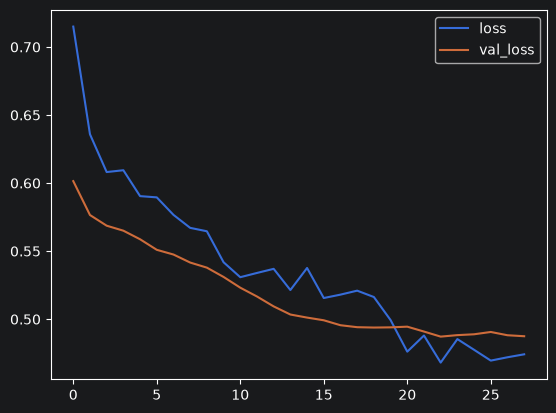

In [113]:
model_loss = pd.DataFrame(model.history.history)
model_loss.plot()

# 3. Evaluación del modelo

In [114]:
from sklearn.metrics import classification_report,confusion_matrix

## 3.1. Predicción sobre el conjunto de Test

In [115]:
#predictions = model.predict_classes(X_test)
predictions = (model.predict(X_test) > 0.5).astype("int32") #Si nueva versión de scikit-learn

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


In [116]:
# https://en.wikipedia.org/wiki/Precision_and_recall
print(classification_report(y_test,predictions))

              precision    recall  f1-score   support

           0       0.78      0.92      0.85       140
           1       0.69      0.40      0.51        60

    accuracy                           0.77       200
   macro avg       0.73      0.66      0.68       200
weighted avg       0.75      0.77      0.74       200



In [117]:
print(confusion_matrix(y_test,predictions))

[[129  11]
 [ 36  24]]


## 3.2. Cargar Modelo Entrenado

In [119]:
import os
from tensorflow.keras.models import load_model

os.makedirs('../models', exist_ok=True)
# Busca la carpeta "models"

ruta_guardado = '../src/train/modelo_pred_binomial.keras'
# Define la ruta relativa desde la ubicación hasta al notebook

model.save(ruta_guardado)
print(f'Modelo guardado en: {ruta_guardado}')

Modelo guardado en: ../src/train/modelo_pred_binomial.keras!
